In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from sklearn import datasets
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve, train_test_split)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp

from Project2b import(
    Runge,
    create_layers,
    feed_forward,
    ReLU,
    LReLU,
    sigmoid,
    softmax,
    softmax_vec,
    identity,
    sigmoid_prime,
    ReLU_prime,
    LReLU_prime,
    identity_prime,
    backpropagation,
    cost,
    train,
    accuracy,
    predict,
    NeuralNetRegressor,
    MSE_2
)
from Project2e import(
    one_hot,
    NeuralNetClassifier,
    accuracy_class
)
from utils import (runge_data, design_matrix, Scaler, MSE, R2, ridge_fit,
                   media_path, save_table, save_text)
from Project1bb import(
    ridge_analysis
)

## Task b

In [2]:
rng = np.random.default_rng(2026)
"""BrokenPipeError
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = Runge(x) + rng.normal(0.0, sigma, n)
X = x.reshape(-1, 1)
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
y = y - np.mean(y)
y = y.reshape(-1,1)
x_test = np.sort(rng.uniform(-1.0, 1.0, n))
y_test = Runge(x_test) + rng.normal(0.0, sigma, n)
X_test = x.reshape(100, 1)
X_test = (X_test - np.mean(X_test, axis=0)) / np.std(X_test, axis=0)
y_test = y_test - np.mean(y_test)
y_test=y_test.reshape(-1,1)
"""
n, sigma = 100, 0.1
x, y = runge_data(n=n, noise=sigma)
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.3, random_state=2026)
degrees=(14,)
ols = ridge_analysis(x_tr, x_te, y_tr, y_te, [0.0], degrees)
print("MSE OLS", ols["mse_te"])

MSE OLS [[0.01452583]]


In [4]:
sc_tr=Scaler().fit(x_tr.reshape(-1,1), y_tr.reshape(-1,1))
X=sc_tr.transform_X(x_tr.reshape(-1,1))
y=y_tr.reshape(-1,1)-sc_tr.y_mean
#print(X)
idx_tr=np.argsort(X[:,0]) #Claude reminded me that argsort existed
X[:]=X[idx_tr]
y[:]=y[idx_tr]
print(X)
sc_te=Scaler().fit(x_te.reshape(-1,1), y_te.reshape(-1,1))
X_test=sc_te.transform_X(x_te.reshape(-1,1))
y_test=y_te.reshape(-1,1)-sc_te.y_mean
idx_te=np.argsort(X_test[:,0])
X_test[:]=X_test[idx_te]
y_test[:]=y_test[idx_te]
"""
X = x_tr.reshape(-1, 1)
y = y_tr.reshape(-1,1)
X_test =x_te.reshape(-1, 1)
y_test=y_te.reshape(-1,1)
"""
#plt.plot(X_test, y_test)

[[-1.99491662e+00]
 [-1.85538649e+00]
 [-1.71963035e+00]
 [-1.71741480e+00]
 [-1.45177855e+00]
 [-1.38389168e+00]
 [-1.37760489e+00]
 [-1.34054948e+00]
 [-1.33796896e+00]
 [-1.31216693e+00]
 [-1.18920153e+00]
 [-9.69467222e-01]
 [-9.03128996e-01]
 [-8.96416434e-01]
 [-8.39787489e-01]
 [-8.19500891e-01]
 [-7.90870230e-01]
 [-7.42106971e-01]
 [-7.17112290e-01]
 [-6.64919286e-01]
 [-6.37295377e-01]
 [-6.16149989e-01]
 [-6.09616086e-01]
 [-4.34218272e-01]
 [-4.33024532e-01]
 [-3.68663807e-01]
 [-3.58526153e-01]
 [-3.09282105e-01]
 [-2.31507190e-01]
 [-2.20764973e-01]
 [-1.51632870e-01]
 [-1.35255216e-01]
 [-1.28788088e-01]
 [-1.01581080e-01]
 [-4.11678434e-02]
 [-2.43519225e-02]
 [ 1.21711915e-03]
 [ 9.13131234e-02]
 [ 1.50516543e-01]
 [ 1.65113908e-01]
 [ 2.05370705e-01]
 [ 2.16702945e-01]
 [ 2.75680225e-01]
 [ 3.01581680e-01]
 [ 3.22758190e-01]
 [ 3.81561229e-01]
 [ 4.38670808e-01]
 [ 4.51213405e-01]
 [ 4.54738799e-01]
 [ 5.33020920e-01]
 [ 5.47224647e-01]
 [ 5.81589109e-01]
 [ 5.9674636

'\nX = x_tr.reshape(-1, 1)\ny = y_tr.reshape(-1,1)\nX_test =x_te.reshape(-1, 1)\ny_test=y_te.reshape(-1,1)\n'

In [4]:

act="sigmoid"
model_1_50=NeuralNetRegressor(hidden=(50,), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_1_50=model_1_50.fit(X, y)
pred_1_50=model_1_50.predict(X_test)


In [5]:
model_1_100=NeuralNetRegressor(hidden=(100,), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_1_100=model_1_100.fit(X, y)
pred_1_100=model_1_100.predict(X_test)

model_2_50=NeuralNetRegressor(hidden=(50, 50), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_2_50=model_2_50.fit(X, y)
pred_2_50=model_2_50.predict(X_test)

model_2_100=NeuralNetRegressor(hidden=(100,100), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_2_100=model_2_100.fit(X, y)
pred_2_100=model_2_100.predict(X_test)

model_50_100=NeuralNetRegressor(hidden=(50,100), activation="sigmoid", epochs=10000, gamma=0.5)
fitted_50_100=model_50_100.fit(X, y)
pred_50_100=model_50_100.predict(X_test)


In [6]:

print("HL 50; MSE:", MSE_2(pred_1_50, y_te))
print("HL 100; MSE", MSE_2(pred_1_100, y_te))
print("HL 50, 50; MSE:", MSE_2(pred_2_50, y_te))
print("HL 100, 50; MSE", MSE_2(pred_2_100, y_te))
print("HL 50, 100; MSE:", MSE_2(pred_50_100, y_te))


HL 50; MSE: 0.22822964550219924
HL 100; MSE 0.23286841660585947
HL 50, 50; MSE: 0.23227111140987267
HL 100, 50; MSE 0.23264084360441586
HL 50, 100; MSE: 0.23383591828516212


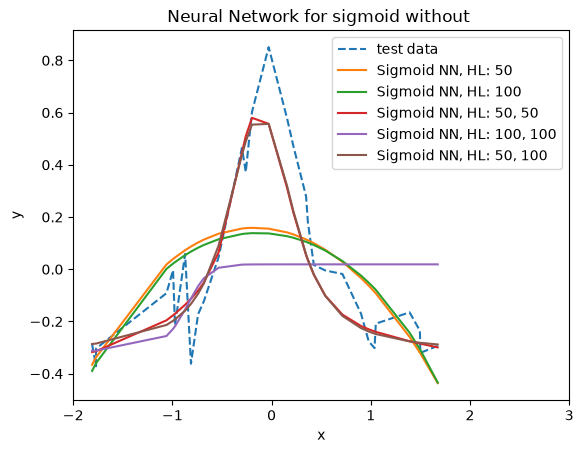

In [14]:
plt.title("Neural Network for sigmoid without ")
plt.plot(X_test, y_test, label="test data", linestyle="dashed")
plt.plot(X_test, pred_1_50, label="Sigmoid NN, HL: 50")
plt.plot(X_test, pred_1_100, label="Sigmoid NN, HL: 100")
plt.plot(X_test, pred_2_50, label="Sigmoid NN, HL: 50, 50")
plt.plot(X_test, pred_2_100, label="Sigmoid NN, HL: 100, 100")
plt.plot(X_test, pred_50_100, label="Sigmoid NN, HL: 50, 100")
plt.xlim(-2, 3)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## Task c

ValueError: x and y must have same first dimension, but have shapes (5,) and (4,)

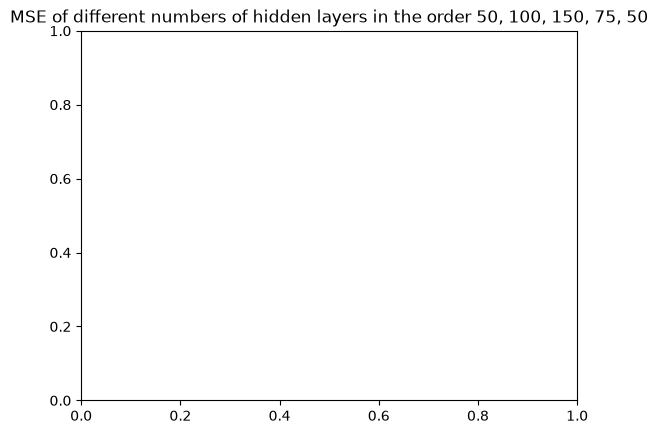

In [ ]:
start=time.time()
ReLU1=NeuralNetRegressor(hidden=(50,), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 1 layer time: ", end-start)
start=time.time()
ReLU2=NeuralNetRegressor(hidden=(50, 100), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 2 layers time: ", end-start)
start=time.time()
ReLU3=NeuralNetRegressor(hidden=(50, 100, 150), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 3 layers time: ", end-start)
start=time.time()
ReLU4=NeuralNetRegressor(hidden=(50,100, 150, 75), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 4 layers time: ", end-start)
start=time.time()
ReLU5=NeuralNetRegressor(hidden=(50,100, 150, 75, 50), activation="relu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("ReLU 5 layers time: ", end-start)

start=time.time()
LReLU1=NeuralNetRegressor(hidden=(50,), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 1 layers time: ", end-start)
start=time.time()
LReLU2=NeuralNetRegressor(hidden=(50, 100), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 2 layers time: ", end-start)
start=time.time()
LReLU3=NeuralNetRegressor(hidden=(50, 100, 150), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 3 layers time: ", end-start)
start=time.time()
LReLU4=NeuralNetRegressor(hidden=(50,100, 150, 75), activation="lrelu", epochs=1000, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 4 layers time: ", end-start)
start=time.time()
LReLU5=NeuralNetRegressor(hidden=(50,100, 150, 75, 50), activation="lrelu", epochs=100, gamma=0.01).fit(X,y)
end=time.time()
print("LReLU 1 layers time: ", end-start)




In [23]:
Sig1=NeuralNetRegressor(hidden=(50,), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig2=NeuralNetRegressor(hidden=(50,100), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig3=NeuralNetRegressor(hidden=(50,100, 150), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig4=NeuralNetRegressor(hidden=(50,100, 150, 75), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)
Sig5=NeuralNetRegressor(hidden=(50,100, 150, 75, 50), activation="sigmoid", epochs=100, gamma=0.01).fit(X,y)

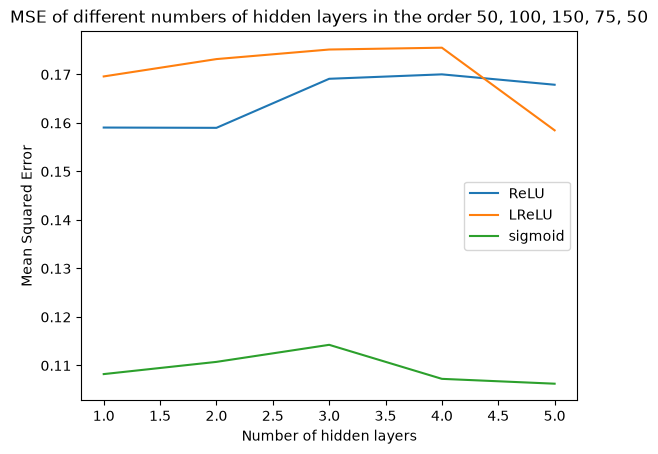

In [24]:

ReLU1_pred, ReLU2_pred, ReLU3_pred, ReLU4_pred, ReLU5_pred=ReLU1.predict(X_test), ReLU2.predict(X_test), ReLU3.predict(X_test), ReLU4.predict(X_test), ReLU5.predict(X_test)
LReLU1_pred, LReLU2_pred, LReLU3_pred, LReLU4_pred, LReLU5_pred=LReLU1.predict(X_test), LReLU2.predict(X_test), LReLU3.predict(X_test), LReLU4.predict(X_test), LReLU5.predict(X_test)
Sig1_pred, Sig2_pred, Sig3_pred, Sig4_pred, Sig5_pred=Sig1.predict(X_test), Sig2.predict(X_test), Sig3.predict(X_test), Sig4.predict(X_test), Sig5.predict(X_test)
R1_MSE,R2_MSE,R3_MSE,R4_MSE,R5_MSE=MSE_2(ReLU1_pred, y_test), MSE_2(ReLU2_pred, y_test), MSE_2(ReLU3_pred, y_test), MSE_2(ReLU4_pred, y_test), MSE_2(ReLU5_pred, y_test)
LR1_MSE,LR2_MSE,LR3_MSE,LR4_MSE,LR5_MSE=MSE_2(LReLU1_pred, y_test), MSE_2(LReLU2_pred, y_test), MSE_2(LReLU3_pred, y_test), MSE_2(LReLU4_pred, y_test), MSE_2(LReLU5_pred, y_test)
S1_MSE, S2_MSE, S3_MSE, S4_MSE, S5_MSE=MSE_2(Sig1_pred, y_test), MSE_2(Sig2_pred, y_test), MSE_2(Sig3_pred, y_test), MSE_2(Sig4_pred, y_test), MSE_2(Sig5_pred, y_test) 
ReLU_MSEs=[R1_MSE, R2_MSE, R3_MSE, R4_MSE, R5_MSE]
LReLU_MSEs=[LR1_MSE, LR2_MSE, LR3_MSE, LR4_MSE, LR5_MSE]
Sig_MSEs=[S1_MSE, S2_MSE, S3_MSE, S4_MSE, S5_MSE]
HLs=[1, 2, 3, 4, 5]
plt.title("MSE of different numbers of hidden layers in the order 50, 100, 150, 75, 50")
plt.plot(HLs, ReLU_MSEs, label="ReLU")
plt.plot(HLs, LReLU_MSEs, label="LReLU")
plt.plot(HLs, Sig_MSEs, label="sigmoid")
plt.legend()
plt.xlabel("Number of hidden layers")
plt.ylabel("Mean Squared Error")
plt.savefig("Plots/nhl_mse.pdf")
plt.show()




## Task d

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
netl2 = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,50), gamma=0.03, activation="sigmoid", epochs=100))
scoresl2 = -cross_val_score(netl2, X, y, cv=cv, scoring="neg_mean_squared_error")
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
param_grid = {"neuralnetregressor__gamma": [0.001, 0.01, 0.1, 0.5, 0.7],
            "neuralnetregressor__lmbd": [0.0, 1e-5, 1e-3, 1e-2, 1e-1]}
searchl2 = GridSearchCV(netl2, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1)
searchl2.fit(X, y)
resultsl2 = searchl2.cv_results_          # a dict of arrays, one entry per grid point


In [12]:

k = 5
gammas = param_grid["neuralnetregressor__gamma"]
lmbds = param_grid["neuralnetregressor__lmbd"]
msel2 = -resultsl2["mean_test_score"].reshape(5, 5)   # rows = gamma, columns = lambda
sel2 = resultsl2["std_test_score"].reshape(5, 5) / np.sqrt(k - 1)
trl2 = -resultsl2["mean_train_score"].reshape(5,5)
i_bestl2 = np.unravel_index(np.argmin(msel2), (5,5))
withinl2 = msel2 <= msel2[i_bestl2] + sel2[i_bestl2]
candl2 = [(j, i) for i in range(5) for j in range(5) if withinl2[i, j]]
j1l2, i1l2 = max(candl2, key=lambda t: (lmbds[t[0]], -gammas[t[1]]))
print("minimum:", searchl2.best_params_, f"CV MSE {msel2[i_bestl2]:.4f} +/- {sel2[i_bestl2]:.4f}")
print(f"1SE choice: gamma = {gammas[i1l2]}, lambda = {lmbds[j1l2]}, CV MSE {msel2[i1l2, j1l2]:.4f} +/- {sel2[i1l2, j1l2]:.4f}")


minimum: {'neuralnetregressor__gamma': 0.5, 'neuralnetregressor__lmbd': 0.001} CV MSE 0.0920 +/- 0.0110
1SE choice: gamma = 0.5, lambda = 0.001, CV MSE 0.0920 +/- 0.0110


In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
netl1 = make_pipeline(StandardScaler(), NeuralNetRegressor(hidden=(50,50), gamma=0.03, activation="sigmoid", epochs=100, L2=False))
scoresl1 = -cross_val_score(netl1, X, y, cv=cv, scoring="neg_mean_squared_error")
cv = KFold(n_splits=5, shuffle=True, random_state=2026)
param_grid = {"neuralnetregressor__gamma": [0.001, 0.01, 0.1, 0.5, 0.7],
            "neuralnetregressor__lmbd": [0.0, 1e-5, 1e-3, 1e-2, 1e-1]}
searchl1 = GridSearchCV(netl1, param_grid, cv=cv, scoring="neg_mean_squared_error", return_train_score=True, n_jobs=-1)
searchl1.fit(X, y)
resultsl1 = searchl1.cv_results_          # a dict of arrays, one entry per grid point


In [10]:
k = 5
gammas = param_grid["neuralnetregressor__gamma"]
lmbds = param_grid["neuralnetregressor__lmbd"]
msel1 = -resultsl1["mean_test_score"].reshape(5, 5)   # rows = gamma, columns = lambda
sel1 = resultsl1["std_test_score"].reshape(5, 5) / np.sqrt(k - 1)
trl1 = -resultsl1["mean_train_score"].reshape(5,5)
i_bestl1 = np.unravel_index(np.argmin(msel1), (5,5))
withinl1 = msel1 <= msel1[i_bestl1] + sel1[i_bestl1]
candl1 = [(j, i) for i in range(5) for j in range(5) if withinl1[i, j]]
j1l1, i1l1 = max(candl1, key=lambda t: (lmbds[t[0]], -gammas[t[1]]))
print("minimum:", searchl1.best_params_, f"CV MSE {msel1[i_bestl1]:.4f} +/- {sel1[i_bestl1]:.4f}")
print(f"1SE choice: gamma = {gammas[i1l1]}, lambda = {lmbds[j1l1]}, CV MSE {msel1[i1l1, j1l1]:.4f} +/- {sel1[i1l1, j1l1]:.4f}")


minimum: {'neuralnetregressor__gamma': 0.5, 'neuralnetregressor__lmbd': 0.001} CV MSE 0.0807 +/- 0.0208
1SE choice: gamma = 0.5, lambda = 0.001, CV MSE 0.0807 +/- 0.0208


## Task e

In [13]:
with np.load("mnist.npz") as data:
        xtr, ytr = data["x_train"], data["y_train"]
        xte, yte = data["x_test"], data["y_test"] # untouched until the end
print(xtr.shape, ytr.shape, xte.shape, yte.shape)
xtr = xtr.reshape(len(xtr), -1) / 255.0
xte = xte.reshape(len(xte), -1) / 255.0
    

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


In [ ]:
model=NeuralNetClassifier(hidden=(50,), activation="sigmoid", epochs=1000, gamma=0.5)
fitted=model.fit(xtr, ytr)
pred=model.predict(xte)


In [15]:
acc=accuracy_class(pred, yte)
print(acc)

0.9747
